# Calibration, and knowing when not to trust a model

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/5_practice/04_calibration_and_probing.ipynb) &nbsp; Guide note: [guide-understanding-and-safety](https://www.matthewwnuk.com/guide-understanding-and-safety.html#calib)

A model that says "95% sure" should be right 95% of the time. This notebook measures how far a small
classifier is from that, adjusts it with one number, and then shows the limit of that adjustment: confidence
means little on inputs unlike the training data.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt
from guide_utils import data, style
style.use()
X, y = data.digits(); X, y = torch.tensor(X), torch.tensor(y)
idx = torch.randperm(len(y), generator=torch.Generator().manual_seed(0)); tr, cal, te = idx[:150], idx[150:600], idx[600:]      # deliberately little training data
torch.manual_seed(0); model = nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 10)); opt = torch.optim.Adam(model.parameters(), 2e-3)
for step in range(300): loss = F.cross_entropy(model(X[tr]), y[tr]); opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad(): logits_cal, logits_te = model(X[cal]), model(X[te])
print(f"training loss {loss.item():.4f}   test accuracy {(logits_te.argmax(1) == y[te]).float().mean():.1%}   mean confidence {logits_te.softmax(1).max(1).values.mean():.1%}")

training loss 0.0003   test accuracy 92.8%   mean confidence 96.6%


The model is more confident than it is accurate. Networks trained to zero training loss generally are.

## Measuring it

Group predictions by confidence and compare each group's average confidence with how often it was right.
The expected calibration error is the average gap, weighted by group size.

In [3]:
def reliability(logits, labels, bins=8):
    conf, pred = logits.softmax(1).max(1); right = (pred == labels).float(); edges = torch.linspace(0.3, 1, bins + 1); rows, ece = [], 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 5: rows.append((conf[m].mean().item(), right[m].mean().item(), int(m.sum())))
        if m.any(): ece += m.float().mean().item() * abs(conf[m].mean().item() - right[m].mean().item())
    return rows, ece
rows, ece = reliability(logits_te, y[te]); print(f"expected calibration error {ece:.3f}")
for c, a, n in rows: print(f"  says {c:.0%} sure -> right {a:.0%} of the time   ({n} predictions)")

expected calibration error 0.039
  says 52% sure -> right 38% of the time   (16 predictions)
  says 60% sure -> right 42% of the time   (19 predictions)
  says 69% sure -> right 59% of the time   (17 predictions)
  says 79% sure -> right 73% of the time   (22 predictions)
  says 87% sure -> right 76% of the time   (54 predictions)
  says 99% sure -> right 97% of the time   (1064 predictions)


## Temperature scaling

Divide the logits by a single number T, chosen on held-out data to minimise the loss. It changes no
prediction, only how sure the model claims to be.
On a model this small the improvement is modest: average confidence comes down toward the accuracy, and
the calibration error falls a little.

best temperature 2.19
mean confidence 96.6% -> 89.7%   (accuracy 92.8%)
expected calibration error 0.039 -> 0.037


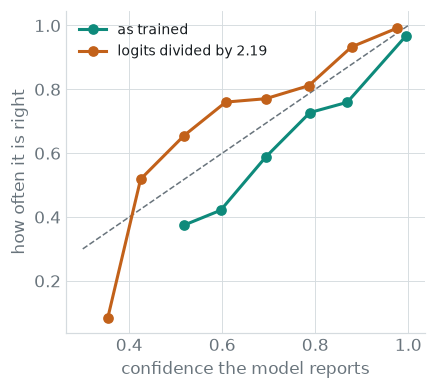

In [4]:
T = torch.ones(1, requires_grad=True); lbfgs = torch.optim.LBFGS([T], lr=0.1, max_iter=200)
def closure(): lbfgs.zero_grad(); l = F.cross_entropy(logits_cal / T, y[cal]); l.backward(); return l
lbfgs.step(closure); T = T.item(); rows2, ece2 = reliability(logits_te / T, y[te])
print(f"best temperature {T:.2f}"); print(f"mean confidence {logits_te.softmax(1).max(1).values.mean():.1%} -> {(logits_te / T).softmax(1).max(1).values.mean():.1%}   (accuracy {(logits_te.argmax(1) == y[te]).float().mean():.1%})"); print(f"expected calibration error {ece:.3f} -> {ece2:.3f}")
plt.figure(figsize=(4.2, 3.8)); plt.plot([0.3, 1], [0.3, 1], color=style.MUTED, ls="--", lw=1)
for r, name in ((rows, "as trained"), (rows2, f"logits divided by {T:.2f}")): plt.plot([c for c, a, n in r], [a for c, a, n in r], marker="o", label=name)
plt.xlabel("confidence the model reports"); plt.ylabel("how often it is right"); plt.legend(fontsize=9); plt.show()

## The limit: inputs unlike the training data

Show the calibrated model things it has never seen: pure noise, and digits turned a quarter turn.

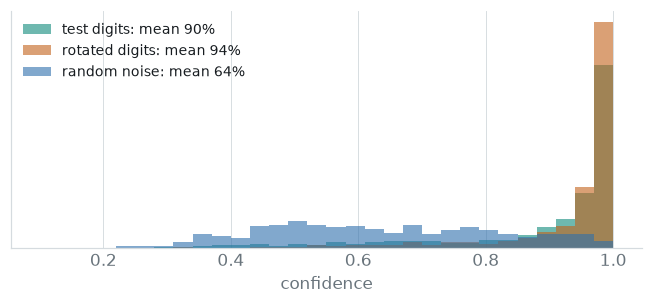

accuracy on rotated digits: 11%, with mean confidence 94%


In [5]:
noise = torch.rand(500, 64); rotated = torch.rot90(X[te].reshape(-1, 8, 8), 1, (1, 2)).reshape(-1, 64)
with torch.no_grad(): conf = {n: (model(x) / T).softmax(1).max(1).values for n, x in (("test digits", X[te]), ("rotated digits", rotated), ("random noise", noise))}
plt.figure(figsize=(7.4, 2.8))
for n, c in conf.items(): plt.hist(c.numpy(), bins=np.linspace(0.1, 1, 31), alpha=0.6, label=f"{n}: mean {c.mean():.0%}", density=True)
plt.xlabel("confidence"); plt.yticks([]); plt.legend(fontsize=9); plt.show()
with torch.no_grad(): print(f"accuracy on rotated digits: {((model(rotated)).argmax(1) == y[te]).float().mean():.0%}, with mean confidence {conf['rotated digits'].mean():.0%}")

The model is confidently wrong on rotated digits. Calibration was measured on inputs like the training
data and says nothing about anything else. A separate check for unfamiliarity is needed.

## A simple unfamiliarity check

Use the network's own hidden features. Measure the distance from each input to its nearest training
example in that feature space.

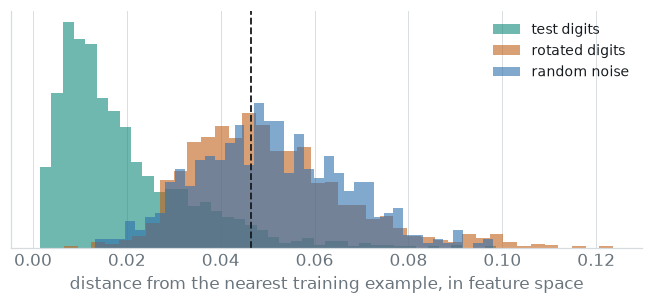

with a threshold that flags 5% of normal test digits: 54% of rotated digits and 59% of noise are flagged


In [6]:
features = lambda x: F.normalize(model[:4](x), dim=-1)
with torch.no_grad(): ref = features(X[tr]); dist = {n: (1 - (features(x) @ ref.T).max(1).values).numpy() for n, x in (("test digits", X[te]), ("rotated digits", rotated), ("random noise", noise))}
thr = np.percentile(dist["test digits"], 95); plt.figure(figsize=(7.4, 2.8))
for n, v in dist.items(): plt.hist(v, bins=40, alpha=0.6, label=n, density=True)
plt.axvline(thr, color=style.INK, ls="--", lw=1.2); plt.xlabel("distance from the nearest training example, in feature space"); plt.yticks([]); plt.legend(fontsize=9); plt.show()
print(f"with a threshold that flags 5% of normal test digits: {np.mean(dist['rotated digits'] > thr):.0%} of rotated digits and {np.mean(dist['random noise'] > thr):.0%} of noise are flagged")

## Things to try

- Train with label smoothing (`F.cross_entropy(..., label_smoothing=0.1)`). Is temperature scaling still needed?
- Use an ensemble of five models and average their probabilities. What happens to confidence on rotated digits?
- A monitor that fires on 5% of normal inputs is too noisy at ten frames a second. Require three alarms in a row and recompute both rates.